# Projekt - TwitterEmo


In [16]:
%pip install datasets pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\Marcin\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [17]:
from datasets import load_dataset

dataset = load_dataset("clarin-pl/twitteremo")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'data', 'tekst', 'radość', 'smutek', 'zaufanie', 'wstręt', 'strach', 'gniew', 'przeczuwanie', 'zdziwienie', 'pozytywny', 'negatywny', 'neutralny', 'ambiwalentny', 'sarkazm'],
        num_rows: 35921
    })
})


In [18]:
print("Dostępne podziały:")
print(dataset.keys())

for split in dataset:
  print("\nNazwa podziału:", split)
  print("Liczba rekordów:", len(dataset[split]))
  print("Nazwy kolumn:", dataset[split].column_names)

  print("\nPrzykładowy rekord:")
  print(dataset[split][0])

Dostępne podziały:
dict_keys(['train'])

Nazwa podziału: train
Liczba rekordów: 35921
Nazwy kolumn: ['id', 'data', 'tekst', 'radość', 'smutek', 'zaufanie', 'wstręt', 'strach', 'gniew', 'przeczuwanie', 'zdziwienie', 'pozytywny', 'negatywny', 'neutralny', 'ambiwalentny', 'sarkazm']

Przykładowy rekord:
{'id': 0, 'data': '2021-09-02', 'tekst': '@anonymized_account jeszcze zaraz będzie rady ministrów i ministra spraw wewnętrznych', 'radość': 0, 'smutek': 0, 'zaufanie': 0, 'wstręt': 0, 'strach': 0, 'gniew': 0, 'przeczuwanie': 0, 'zdziwienie': 0, 'pozytywny': 0, 'negatywny': 0, 'neutralny': 1, 'ambiwalentny': 0, 'sarkazm': 0}


In [19]:
EMOTIONS = ["radość", "smutek", "zaufanie", "wstręt", "strach", "gniew", "przeczuwanie", "zdziwienie"]

texts = dataset["train"]["tekst"]

labels = list(zip(*[dataset["train"][emo] for emo in EMOTIONS]))

print(texts[0])
print(labels[0])
print(len(labels))

@anonymized_account jeszcze zaraz będzie rady ministrów i ministra spraw wewnętrznych
(0, 0, 0, 0, 0, 0, 0, 0)
35921


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

EMOTIONS = ["radość", "smutek", "zaufanie", "wstręt", "strach", "gniew", "przeczuwanie", "zdziwienie"]

texts = dataset["train"]["tekst"]
y = np.stack([dataset["train"][emo] for emo in EMOTIONS], axis=1).astype(np.float32)

print("Kształt etykiet:", y.shape)
print("Suma etykiet per emocja:", dict(zip(EMOTIONS, y.sum(axis=0).astype(int))))

Kształt etykiet: (35921, 8)
Suma etykiet per emocja: {'radość': np.int64(4130), 'smutek': np.int64(1669), 'zaufanie': np.int64(1618), 'wstręt': np.int64(8320), 'strach': np.int64(323), 'gniew': np.int64(6333), 'przeczuwanie': np.int64(12602), 'zdziwienie': np.int64(2339)}


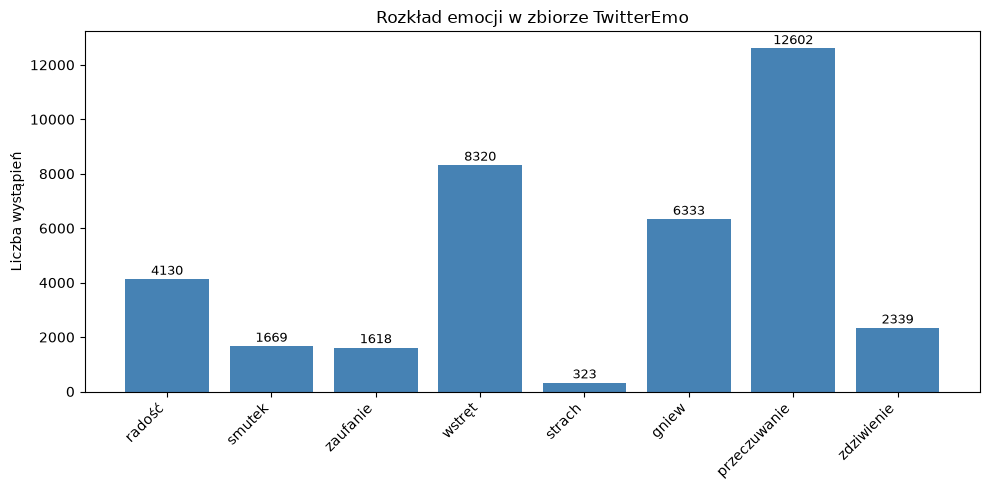

In [21]:
label_counts = y.sum(axis=0).astype(int)

plt.figure(figsize=(10, 5))
bars = plt.bar(EMOTIONS, label_counts, color="steelblue")
plt.title("Rozkład emocji w zbiorze TwitterEmo")
plt.ylabel("Liczba wystąpień")
plt.xticks(rotation=45, ha="right")

# wartości nad słupkami
for bar, count in zip(bars, label_counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             str(count), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

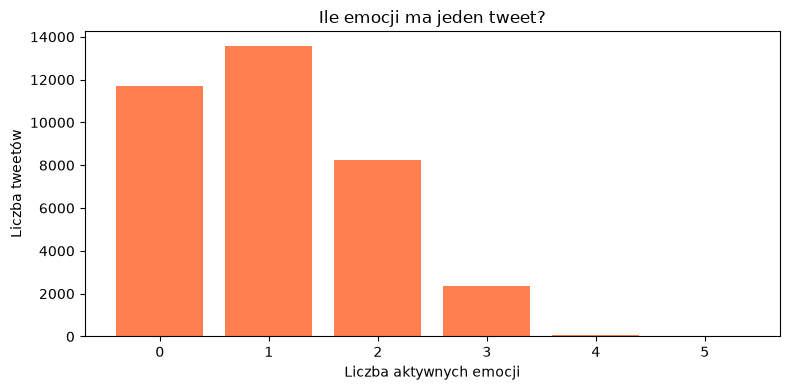

Tweetów bez żadnej emocji: 11688
Tweetów z ≥2 emocjami: 10656


In [22]:
labels_per_tweet = y.sum(axis=1).astype(int)

plt.figure(figsize=(8, 4))
counts = pd.Series(labels_per_tweet).value_counts().sort_index()
plt.bar(counts.index, counts.values, color="coral")
plt.title("Ile emocji ma jeden tweet?")
plt.xlabel("Liczba aktywnych emocji")
plt.ylabel("Liczba tweetów")
plt.xticks(range(0, int(labels_per_tweet.max()) + 1))
plt.tight_layout()
plt.show()

print("Tweetów bez żadnej emocji:", (labels_per_tweet == 0).sum())
print("Tweetów z ≥2 emocjami:", (labels_per_tweet >= 2).sum())

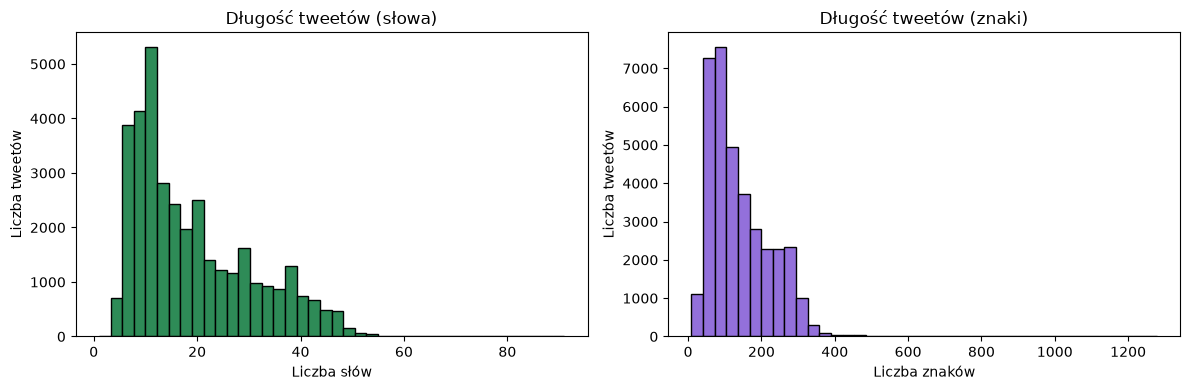

Średnia długość (słowa): 19.0
Mediana długości (słowa): 15.0
Max słów: 91


In [23]:
text_lengths = [len(t.split()) for t in texts]  # liczba słów
char_lengths = [len(t) for t in texts]          # liczba znaków

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(text_lengths, bins=40, color="seagreen", edgecolor="black")
axes[0].set_title("Długość tweetów (słowa)")
axes[0].set_xlabel("Liczba słów")
axes[0].set_ylabel("Liczba tweetów")

axes[1].hist(char_lengths, bins=40, color="mediumpurple", edgecolor="black")
axes[1].set_title("Długość tweetów (znaki)")
axes[1].set_xlabel("Liczba znaków")
axes[1].set_ylabel("Liczba tweetów")

plt.tight_layout()
plt.show()

print(f"Średnia długość (słowa): {np.mean(text_lengths):.1f}")
print(f"Mediana długości (słowa): {np.median(text_lengths):.1f}")
print(f"Max słów: {max(text_lengths)}")

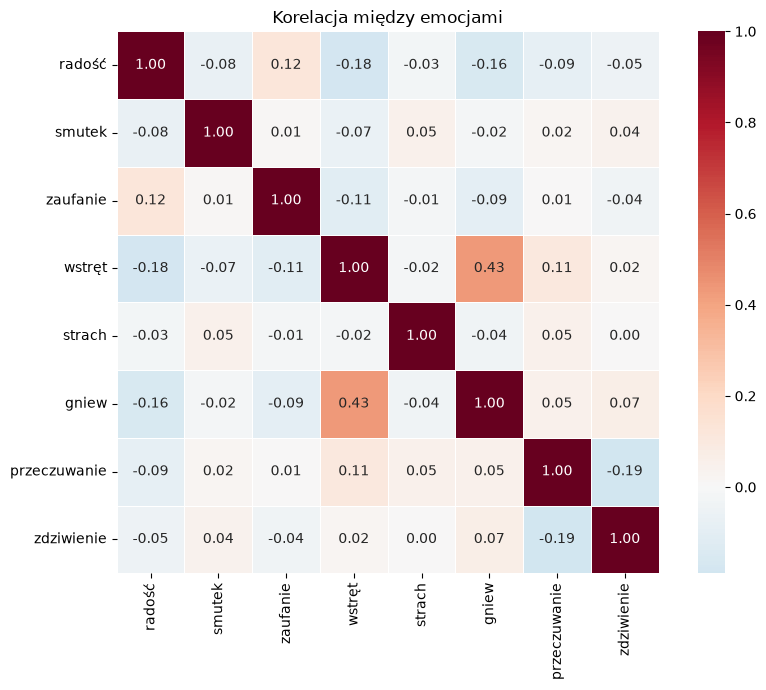

In [24]:
corr = pd.DataFrame(y, columns=EMOTIONS).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5)
plt.title("Korelacja między emocjami")
plt.tight_layout()
plt.show()

In [25]:
# pokazanie 5 tweetów, które mają ≥ 2 emocje
multi_idx = np.where(labels_per_tweet >= 2)[0][:5]

for i in multi_idx:
    active = [EMOTIONS[j] for j in range(8) if y[i, j] == 1]
    print(f"Tekst: {texts[i]}")
    print(f"Emocje: {active}")
    print("-" * 60)

Tekst: @anonymized_account Ten kto go zaprosił życzy dobrze przede wszystkim sobie a co by nie mówić to za takiego Bońka trochę przytuli z reklam.
Emocje: ['wstręt', 'gniew']
------------------------------------------------------------
Tekst: @anonymized_account I się tumanie zdziwisz. Obiecaj że jak większość bedze chciala Unii to wyjedziesz na Białoruś
Emocje: ['wstręt', 'gniew']
------------------------------------------------------------
Tekst: @anonymized_account Był tam też pan, który na pytania o łamanie Konstytucji, nie bardzo miał co odpowiedzieć, ale za to dodał, z wielkim przekonaniem, że oni szkalują nas w Brukseli      Przekazy żywcem z tvpis
Emocje: ['wstręt', 'gniew']
------------------------------------------------------------
Tekst: @anonymized_account Wielu z nas wiedziało już od wielu lat, że zmierzamy do totalnego upadku. Niestety jest nas, świadomych za mało. Myślę, że jednym z przejawów dalszego upadku będzie popadnięcie Europy i świata w autorytaryzmy. Każdy z na